In [2]:
import os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_style("whitegrid")

FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
path = f"dataset/{FILE}" if os.path.exists(f"dataset/{FILE}") else f"../dataset/{FILE}"

df = pd.read_csv(path)
print(df.shape)
df.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [4]:
blank = df["TotalCharges"].astype(str).str.strip() == ""
print("Nulls:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Blank TotalCharges:", blank.sum())
df[blank][["tenure", "TotalCharges"]].head()

Nulls: 0
Duplicate rows: 0
Blank TotalCharges: 11


,tenure,TotalCharges
488,0,
753,0,
936,0,
1082,0,
1340,0,


In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


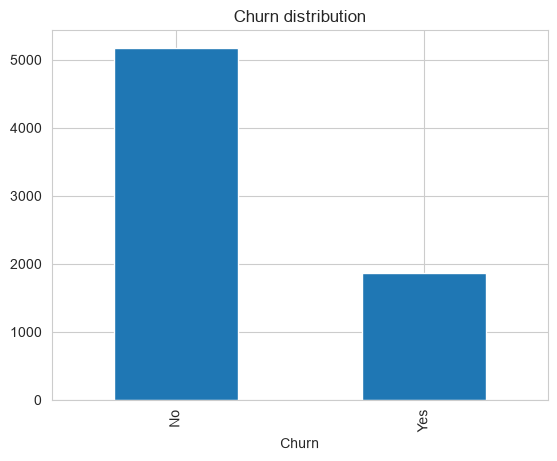

In [6]:
print(df["Churn"].value_counts(normalize=True).round(3))
df["Churn"].value_counts().plot.bar(title="Churn distribution")
plt.show()

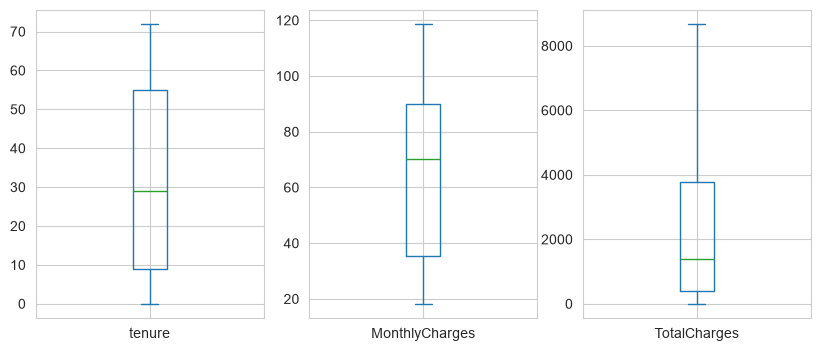

tenure IQR outliers: 0
MonthlyCharges IQR outliers: 0
TotalCharges IQR outliers: 0


In [7]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
df[num_cols].plot.box(subplots=True, figsize=(10, 4))
plt.show()
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(c, "IQR outliers:", n)

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: ChurnFlag, dtype: float64 



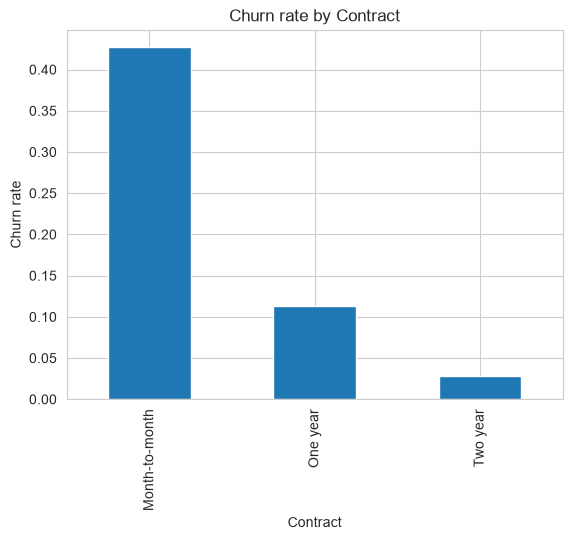

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: ChurnFlag, dtype: float64 



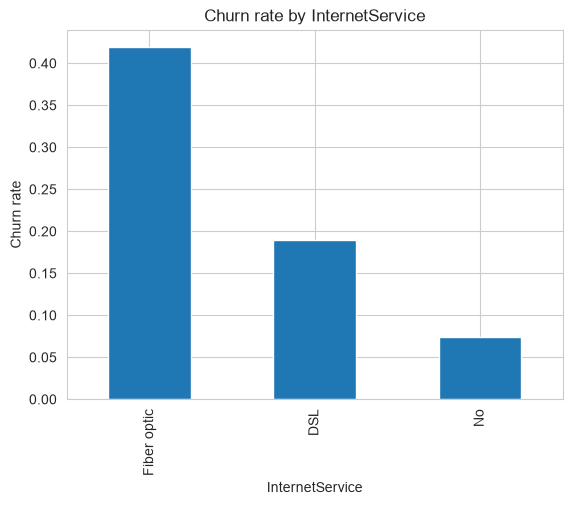

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: ChurnFlag, dtype: float64 



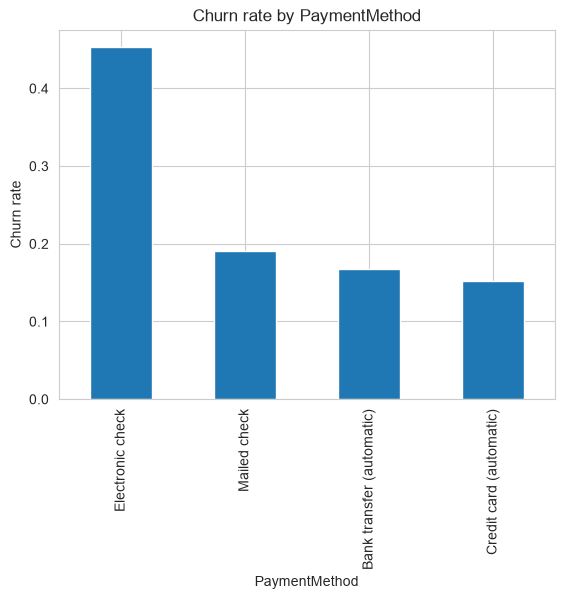

TechSupport
No                     0.416
Yes                    0.152
No internet service    0.074
Name: ChurnFlag, dtype: float64 



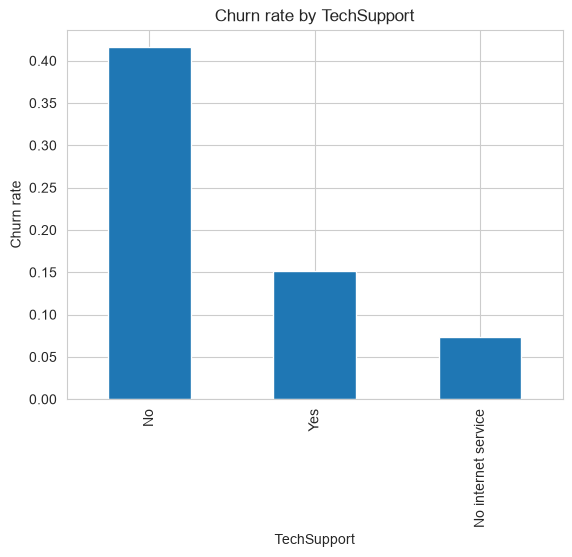

OnlineSecurity
No                     0.418
Yes                    0.146
No internet service    0.074
Name: ChurnFlag, dtype: float64 



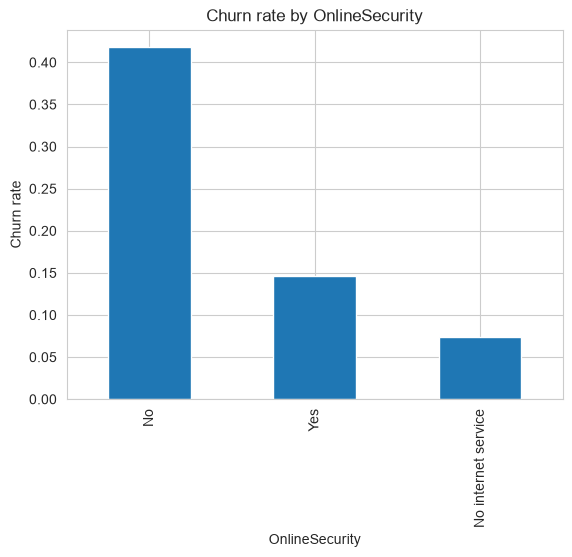

SeniorCitizen
1    0.417
0    0.236
Name: ChurnFlag, dtype: float64 



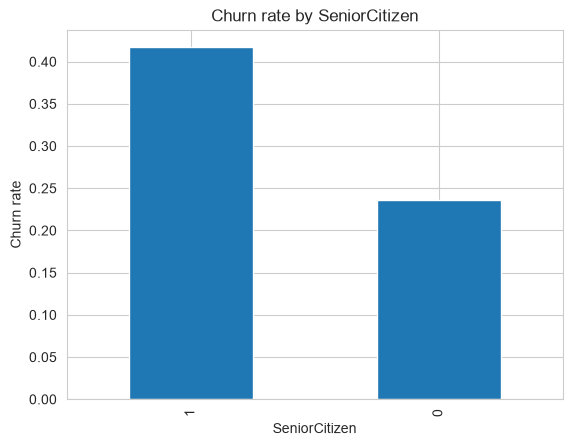

In [9]:
cat_cols = ["Contract", "InternetService", "PaymentMethod",
            "TechSupport", "OnlineSecurity", "SeniorCitizen"]
for c in cat_cols:
    rate = df.groupby(c)["ChurnFlag"].mean().sort_values(ascending=False).round(3)
    print(rate, "\n")
    rate.plot.bar(title=f"Churn rate by {c}")
    plt.ylabel("Churn rate")
    plt.show()

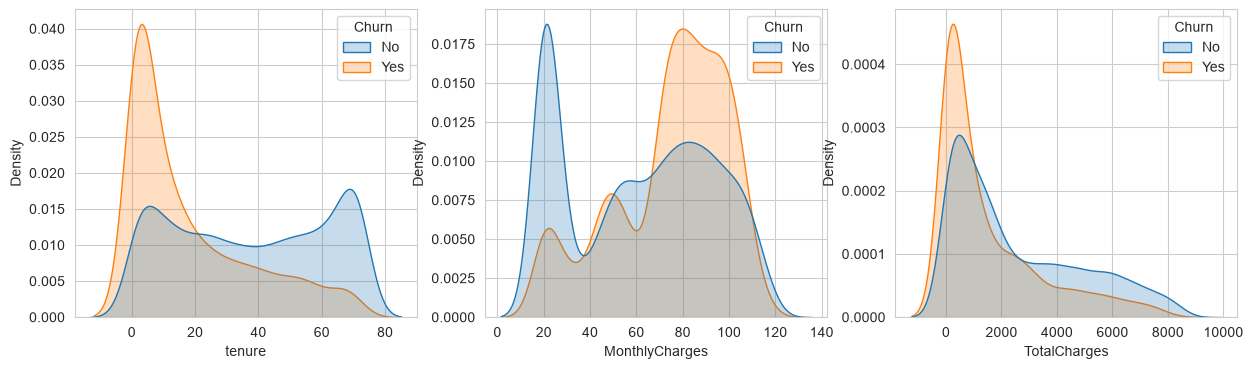

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No      37.57           61.27       2549.91
Yes     17.98           74.44       1531.80


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, num_cols):
    sns.kdeplot(data=df, x=c, hue="Churn", fill=True, common_norm=False, ax=a)
plt.show()
print(df.groupby("Churn")[num_cols].mean().round(2))

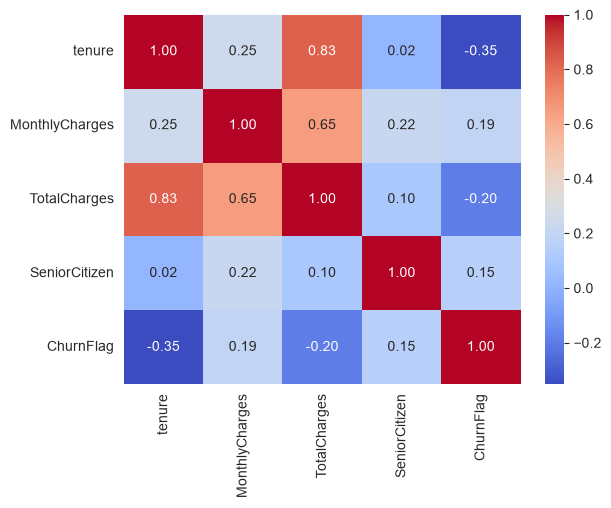

In [11]:
corr = df[num_cols + ["SeniorCitizen", "ChurnFlag"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

In [12]:
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12", "13-24", "25-48", "49-72"])
print(df.groupby("TenureGroup", observed=True)["ChurnFlag"].mean().round(3))

TenureGroup
0-12     0.474
13-24    0.287
25-48    0.204
49-72    0.095
Name: ChurnFlag, dtype: float64
